# Emergency department simulation (full model)

The model built live in the Week 04 session: patients are triaged (one nurse, 4–8 minutes), then seen by doctors.
Critical patients pre-empt urgent ones, and urgent pre-empt standard. Arrivals vary by time of day (3, 6 and 4 per hour).
The experiment compares 2–5 doctors over 40 replications, with 95% confidence intervals.

*Original script: `5 Source Files/Python/hospital_sim.py` (kept unchanged). One correction (erratum C10): doctor and triage
utilisation now count busy time as it happens. The original counted it only for patients already discharged, so it read
0.66 instead of 0.72 for 2 doctors. Waits are still measured for patients who were seen. Patients still waiting at the end
of the 12-hour shift are not in the averages, so with 2 doctors the true waits are a little longer. Run the cells in order;
the first cell installs SimPy.*

The staged version of this model (Stages 1–5, as built in the session) is `1 Building the ED simulation in stages.ipynb`.

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install simpy

In [2]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

**Version A (Year 2): ED with triage + priority + preemption.**

In [3]:
# =========================================================
# Version A (Year 2): ED with triage + priority + preemption
# CLEANED + CORRECTED
#   - Wait time measured as: (doctor_start - after_triage_time)
#   - Preemption handled correctly with resume
#   - Busy time accounted from actual served segments (no double count)
#   - Fair comparisons via replications and controlled seeding
# =========================================================

# ----------------------------
# Global parameters
# ----------------------------
SIM_HOURS = 12
SIM_TIME = SIM_HOURS * 60  # minutes

TRIAGE_TIME_MIN = 4
TRIAGE_TIME_MAX = 8

SERVICE_MEANS = {  # minutes
    "critical": 40,
    "urgent": 30,
    "standard": 20,
}

PRIORITY = {       # lower = higher priority in SimPy
    "critical": 0,
    "urgent": 1,
    "standard": 2,
}

PATIENT_MIX = {    # probabilities
    "critical": 0.10,
    "urgent": 0.30,
    "standard": 0.60,
}

**Service targets (minutes) — edit as you wish.**

In [4]:
# Service targets (minutes) — edit as you wish
TARGETS = {
    "critical": 10,
    "urgent": 10,
    "standard": 30,
}

**Costs.**

In [5]:
# Costs
DOCTOR_COST_PER_HOUR = 40
DISSAT_COST_PER_MIN = {
    "critical": 5,
    "urgent": 5,
    "standard": 1,
}

**Time-varying arrival rate (per hour).**

In [6]:
# ----------------------------
# Time-varying arrival rate (per hour)
# ----------------------------
def arrival_rate_per_hour(t_min: float) -> float:
    """Piecewise arrival rates by time-of-day (t in minutes)."""
    if t_min < 4 * 60:
        return 3
    elif t_min < 8 * 60:
        return 6
    else:
        return 4


def sample_patient_type() -> str:
    r = random.random()
    if r < PATIENT_MIX["critical"]:
        return "critical"
    if r < PATIENT_MIX["critical"] + PATIENT_MIX["urgent"]:
        return "urgent"
    return "standard"


def sample_service_time(patient_type: str) -> float:
    """Gamma/lognormal would be more realistic; keep exponential for teachability."""
    mean = SERVICE_MEANS[patient_type]
    return random.expovariate(1 / mean)


def sample_triage_time() -> float:
    return random.uniform(TRIAGE_TIME_MIN, TRIAGE_TIME_MAX)

**`Stats`** (class).

In [7]:
# ----------------------------
# Stats
# ----------------------------
class Stats:
    def __init__(self):
        # doctor-wait only (post-triage to doctor start)
        self.wait_doctor = {"critical": [], "urgent": [], "standard": []}

        # (optional) total time in system (arrival to discharge)
        self.time_in_system = {"critical": [], "urgent": [], "standard": []}

        # interruptions (count) for standard patients
        self.standard_interruptions = []

        # throughput
        self.total_patients = 0
        self.count_by_type = {"critical": 0, "urgent": 0, "standard": 0}

        # utilisation components (busy minutes)
        self.doctor_busy = 0.0
        self.triage_busy = 0.0

    def record(self, ptype, wait_doc, tis, std_interruptions, doc_served, tri_served):
        self.wait_doctor[ptype].append(wait_doc)
        self.time_in_system[ptype].append(tis)
        self.total_patients += 1
        self.count_by_type[ptype] += 1

        if ptype == "standard":
            self.standard_interruptions.append(std_interruptions)

        self.doctor_busy += doc_served
        self.triage_busy += tri_served

**`BusyTracker`** (class): Time-weighted count of busy servers. total() = busy server-minutes so far.

In [8]:
# ----------------------------
# Busy-time tracker (added: exact utilisation, including work still in progress at the end of the run)
# ----------------------------
class BusyTracker:
    """Time-weighted count of busy servers. total() = busy server-minutes so far."""
    def __init__(self, env):
        self.env = env
        self.busy = 0
        self.area = 0.0
        self.last = 0.0

    def change(self, delta):
        self.area += self.busy * (self.env.now - self.last)
        self.last = self.env.now
        self.busy += delta

    def total(self):
        return self.area + self.busy * (self.env.now - self.last)

**`patient`** (function).

In [9]:
# ----------------------------
# Patient process
# ----------------------------
def patient(env: simpy.Environment, ptype: str, triage: simpy.Resource,
            doctors: simpy.PreemptiveResource, stats: Stats):

    arrival = env.now

    # ---- TRIAGE ----
    tri_queue_enter = env.now
    with triage.request() as req_t:
        yield req_t
        stats.tri_tracker.change(+1)
        tri_duration = sample_triage_time()
        yield env.timeout(tri_duration)
        stats.tri_tracker.change(-1)

    after_triage = env.now
    tri_served = tri_duration  # triage is busy exactly during service

    # ---- DOCTOR (preemptive, resume) ----
    service_total = sample_service_time(ptype)
    remaining = service_total
    std_interruptions = 0

    # waiting for doctor measured from after triage
    first_doctor_start = None
    doc_served_total = 0.0

    while remaining > 1e-9:
        with doctors.request(priority=PRIORITY[ptype], preempt=True) as req_d:
            yield req_d
            seg_start = env.now
            stats.doc_tracker.change(+1)

            if first_doctor_start is None:
                first_doctor_start = seg_start  # first time they get a doctor

            try:
                # attempt to finish remaining service
                yield env.timeout(remaining)
                seg_end = env.now
                stats.doc_tracker.change(-1)
                served = seg_end - seg_start
                doc_served_total += served
                remaining = 0.0

            except simpy.Interrupt:
                seg_end = env.now
                stats.doc_tracker.change(-1)
                served = seg_end - seg_start
                doc_served_total += served
                remaining = max(0.0, remaining - served)

                if ptype == "standard":
                    std_interruptions += 1

    discharge = env.now

    # Metrics
    wait_doctor = (first_doctor_start - after_triage) if first_doctor_start is not None else 0.0
    tis = discharge - arrival

    stats.record(
        ptype=ptype,
        wait_doc=wait_doctor,
        tis=tis,
        std_interruptions=std_interruptions,
        doc_served=doc_served_total,
        tri_served=tri_served
    )

**`arrivals`** (function).

In [10]:
# ----------------------------
# Arrival process
# ----------------------------
def arrivals(env: simpy.Environment, triage: simpy.Resource,
             doctors: simpy.PreemptiveResource, stats: Stats):
    while True:
        lam_per_hr = arrival_rate_per_hour(env.now)
        lam_per_min = lam_per_hr / 60.0
        interarrival = random.expovariate(lam_per_min)
        yield env.timeout(interarrival)

        ptype = sample_patient_type()
        env.process(patient(env, ptype, triage, doctors, stats))

**`run_once`** (function).

In [11]:
# ----------------------------
# Single run
# ----------------------------
def run_once(num_doctors: int, *, seed: int, sim_time: int = SIM_TIME) -> dict:
    random.seed(seed)

    env = simpy.Environment()
    stats = Stats()
    stats.doc_tracker = BusyTracker(env)
    stats.tri_tracker = BusyTracker(env)

    triage = simpy.Resource(env, capacity=1)
    doctors = simpy.PreemptiveResource(env, capacity=num_doctors)

    env.process(arrivals(env, triage, doctors, stats))
    env.run(until=sim_time)

    # Analyse
    out = {}

    for ptype in ["critical", "urgent", "standard"]:
        waits = np.array(stats.wait_doctor[ptype], dtype=float)
        tis = np.array(stats.time_in_system[ptype], dtype=float)

        if waits.size == 0:
            out[ptype] = {
                "n": 0, "avg_wait": np.nan, "pct_target": np.nan, "avg_tis": np.nan
            }
            continue

        out[ptype] = {
            "n": int(waits.size),
            "avg_wait": float(np.mean(waits)),
            "pct_target": float(100.0 * np.mean(waits < TARGETS[ptype])),
            "avg_tis": float(np.mean(tis)),
        }

    # Utilisation
    # corrected: busy time counted as it happens (the original only counted patients already discharged)
    doc_util = stats.doc_tracker.total() / (num_doctors * sim_time)
    tri_util = stats.tri_tracker.total() / sim_time

    # Interruptions (standard only)
    avg_std_interruptions = float(np.mean(stats.standard_interruptions)) if stats.standard_interruptions else 0.0

    # Costs
    doctor_cost = num_doctors * DOCTOR_COST_PER_HOUR * SIM_HOURS

    diss_cost = 0.0
    for ptype in ["critical", "urgent", "standard"]:
        diss_cost += float(np.sum(stats.wait_doctor[ptype])) * DISSAT_COST_PER_MIN[ptype]

    total_cost = doctor_cost + diss_cost

    out["system"] = {
        "patients_total": stats.total_patients,
        "doctor_util": float(doc_util),
        "triage_util": float(tri_util),
        "avg_std_interruptions": avg_std_interruptions,
        "doctor_cost": float(doctor_cost),
        "dissatisfaction_cost": float(diss_cost),
        "total_cost": float(total_cost),
    }

    return out

**Replications + summary (mean + CI).**

In [12]:
# ----------------------------
# Replications + summary (mean + CI)
# ----------------------------
def mean_ci(x: np.ndarray, alpha: float = 0.05):
    """Normal-approx CI is fine for teaching; reps>=30 recommended."""
    x = np.asarray(x, dtype=float)
    m = float(np.mean(x))
    s = float(np.std(x, ddof=1)) if x.size > 1 else 0.0
    se = s / np.sqrt(x.size) if x.size > 0 else np.nan
    z = 1.96  # ~95%
    return m, m - z * se, m + z * se


def run_experiment(doctor_range=(2, 3, 4, 5), reps=40, base_seed=1000, sim_time=SIM_TIME):
    results = {d: [] for d in doctor_range}
    for r in range(reps):
        seed = base_seed + r
        for d in doctor_range:
            results[d].append(run_once(d, seed=seed, sim_time=sim_time))
    return results


def summarise_experiment(raw, doctor_range=(2, 3, 4, 5)):
    summary = {}

    for d in doctor_range:
        std_avg_wait = np.array([run["standard"]["avg_wait"] for run in raw[d]], dtype=float)
        urg_pct_target = np.array([run["urgent"]["pct_target"] for run in raw[d]], dtype=float)
        std_pct_target = np.array([run["standard"]["pct_target"] for run in raw[d]], dtype=float)
        total_cost = np.array([run["system"]["total_cost"] for run in raw[d]], dtype=float)

        summary[d] = {
            "std_avg_wait_mean_ci": mean_ci(std_avg_wait),
            "urg_pct_target_mean_ci": mean_ci(urg_pct_target),
            "std_pct_target_mean_ci": mean_ci(std_pct_target),
            "total_cost_mean_ci": mean_ci(total_cost),
            "doc_util_mean": float(np.mean([run["system"]["doctor_util"] for run in raw[d]])),
            "tri_util_mean": float(np.mean([run["system"]["triage_util"] for run in raw[d]])),
            "avg_std_interruptions_mean": float(np.mean([run["system"]["avg_std_interruptions"] for run in raw[d]])),
        }

    return summary

**Demo: run + plot.**

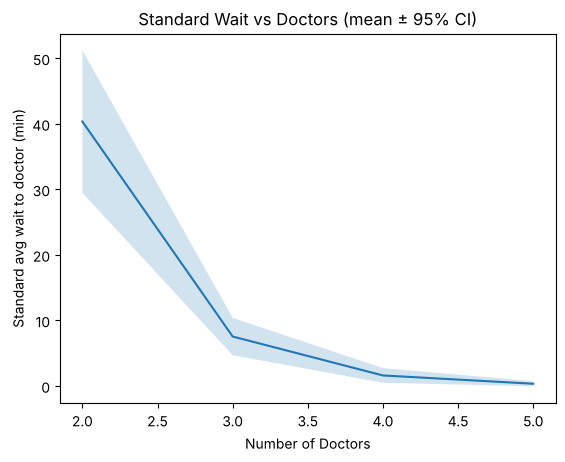

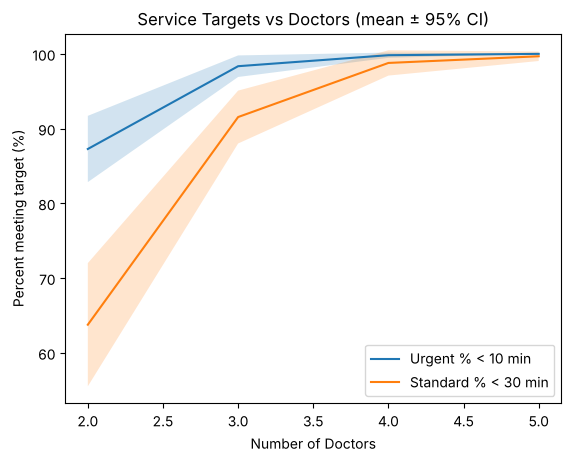

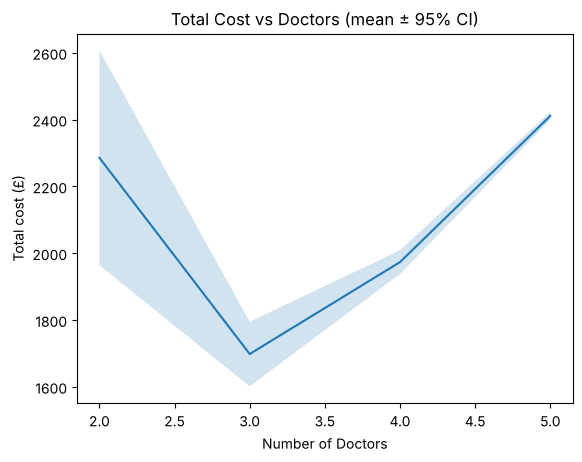

2 doctors | Std avg wait=40.35 min | Urgent target=87.3% | Std target=63.8% | Doc util=0.72 | Triage util=0.41 | Avg std interruptions=0.21 | Total cost=2286
3 doctors | Std avg wait=7.54 min | Urgent target=98.3% | Std target=91.5% | Doc util=0.53 | Triage util=0.41 | Avg std interruptions=0.15 | Total cost=1698
4 doctors | Std avg wait=1.60 min | Urgent target=99.8% | Std target=98.8% | Doc util=0.40 | Triage util=0.41 | Avg std interruptions=0.06 | Total cost=1974
5 doctors | Std avg wait=0.34 min | Urgent target=100.0% | Std target=99.7% | Doc util=0.32 | Triage util=0.41 | Avg std interruptions=0.02 | Total cost=2411


In [13]:
# ----------------------------
# Demo: run + plot
# ----------------------------
if __name__ == "__main__":
    doctor_range = [2, 3, 4, 5]
    reps = 40

    raw = run_experiment(doctor_range=doctor_range, reps=reps, base_seed=20240, sim_time=SIM_TIME)
    summ = summarise_experiment(raw, doctor_range=doctor_range)

    # Plot 1: Standard avg wait with CI
    xs = doctor_range
    ys = [summ[d]["std_avg_wait_mean_ci"][0] for d in xs]
    lo = [summ[d]["std_avg_wait_mean_ci"][1] for d in xs]
    hi = [summ[d]["std_avg_wait_mean_ci"][2] for d in xs]

    plt.figure()
    plt.plot(xs, ys)
    plt.fill_between(xs, lo, hi, alpha=0.2)
    plt.xlabel("Number of Doctors")
    plt.ylabel("Standard avg wait to doctor (min)")
    plt.title("Standard Wait vs Doctors (mean ± 95% CI)")
    plt.show()

    # Plot 2: Target attainment (urgent <10, standard <30) with CI
    urg = [summ[d]["urg_pct_target_mean_ci"][0] for d in xs]
    urg_lo = [summ[d]["urg_pct_target_mean_ci"][1] for d in xs]
    urg_hi = [summ[d]["urg_pct_target_mean_ci"][2] for d in xs]

    std = [summ[d]["std_pct_target_mean_ci"][0] for d in xs]
    std_lo = [summ[d]["std_pct_target_mean_ci"][1] for d in xs]
    std_hi = [summ[d]["std_pct_target_mean_ci"][2] for d in xs]

    plt.figure()
    plt.plot(xs, urg, label="Urgent % < 10 min")
    plt.fill_between(xs, urg_lo, urg_hi, alpha=0.2)

    plt.plot(xs, std, label="Standard % < 30 min")
    plt.fill_between(xs, std_lo, std_hi, alpha=0.2)

    plt.xlabel("Number of Doctors")
    plt.ylabel("Percent meeting target (%)")
    plt.title("Service Targets vs Doctors (mean ± 95% CI)")
    plt.legend()
    plt.show()

    # Plot 3: Total cost with CI
    cost = [summ[d]["total_cost_mean_ci"][0] for d in xs]
    cost_lo = [summ[d]["total_cost_mean_ci"][1] for d in xs]
    cost_hi = [summ[d]["total_cost_mean_ci"][2] for d in xs]

    plt.figure()
    plt.plot(xs, cost)
    plt.fill_between(xs, cost_lo, cost_hi, alpha=0.2)
    plt.xlabel("Number of Doctors")
    plt.ylabel("Total cost (£)")
    plt.title("Total Cost vs Doctors (mean ± 95% CI)")
    plt.show()

    # Quick text summary
    for d in xs:
        print(
            f"{d} doctors | "
            f"Std avg wait={summ[d]['std_avg_wait_mean_ci'][0]:.2f} min | "
            f"Urgent target={summ[d]['urg_pct_target_mean_ci'][0]:.1f}% | "
            f"Std target={summ[d]['std_pct_target_mean_ci'][0]:.1f}% | "
            f"Doc util={summ[d]['doc_util_mean']:.2f} | "
            f"Triage util={summ[d]['tri_util_mean']:.2f} | "
            f"Avg std interruptions={summ[d]['avg_std_interruptions_mean']:.2f} | "
            f"Total cost={summ[d]['total_cost_mean_ci'][0]:.0f}"
        )